### Notebook 3c — Quality Assessment of the Synthetic Images and Final Synthetic Dataset

> Select the best DC-GAN checkpoint, quantify the quality of the DC-GAN and RoentGen-v2 images with several complementary measures, check for shortcuts (real-vs-synthetic detectability, view position) and memorisation, and export the final synthetic manifest used by the classification notebooks.

**Inputs to attach** (+ Add Input): the NIH ChestX-ray14 dataset (same one as Notebooks 1-3), the output of Notebook 2 (splits), the output of Notebook 3a (checkpoints) and the outputs of the Notebook 3b runs (`pos` and `neg`; add both).

**What it does**

1. Loads the real images (training 5K and held-out validation) with the common resizing pipeline (224 × 224).
2. Selects the DC-GAN checkpoint with the lowest KID against held-out real validation images, and regenerates the final 5,000 + 2,500 DC-GAN images with it.
3. Quality metrics for each generator and class: FID, KID (TorchXRayVision features, and Inception features when the weights are available), Inception Score, MS-SSIM diversity and SSIM to the nearest real image.
4. Real-versus-synthetic detector (deep features and simple pixel statistics), with a breakdown by view position and a resolution-matched reference for the DC-GAN.
5. Memorisation screen with deep features.
6. Alignment diagnostic: does the TorchXRayVision *Pneumonia* output separate synthetic pneumonia from synthetic normal images? (diagnostic only; it is never used to filter images).
7. Exports `synthetic_final_manifest.csv` and the metric tables.

### 1. Configuration and Input Discovery

In [1]:
import os, json, math, time, random, warnings
from glob import glob
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
warnings.filterwarnings('ignore')

SEED = 42
INPUT_ROOT, WORK = '/kaggle/input', Path('/kaggle/working')
OUT = WORK / 'quality'; FINAL_DIR = WORK / 'synthetic' / 'dcgan_final'
for d in (OUT, FINAL_DIR / 'pneumonia', FINAL_DIR / 'no_finding'):
    d.mkdir(parents=True, exist_ok=True)

EVAL_SIZE = 224          # classifier input size; every image goes through the same resizing pipeline
N_CKPT_SAMPLES = 1000    # images per checkpoint for the checkpoint selection
N_EVAL = 1500            # images per generator and class used for the metrics
N_VAL_NEG = 500          # held-out real negatives
N_SYN = {'pos': 5000, 'neg': 2500}
FORCE_CKPT = {'pos': None, 'neg': None}    # e.g. {'pos': 'pos_ema_it015000.pt'} to override the automatic choice
NZ, NGF, IMG_SIZE = 100, 64, 128           # must match Notebook 3a

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU (slow)')
def set_seed(s): random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)

# --- one walk over the inputs (the NIH image folders are skipped) ---
ALL_FILES = []
for cur, dirs, files in os.walk(INPUT_ROOT):
    dirs[:] = [d for d in dirs if d != 'images']
    ALL_FILES += [os.path.join(cur, f) for f in files]
by_name = lambda n: [p for p in ALL_FILES if os.path.basename(p) == n]
print(f'{len(ALL_FILES):,} files found under {INPUT_ROOT}')

h = by_name('real_5k.csv');          assert h, 'real_5k.csv not found: attach the output of Notebook 2'
SPLITS_DIR = os.path.dirname(h[0])
h = by_name('pos_ema_final.pt');     assert h, 'DC-GAN checkpoints not found: attach the output of Notebook 3a'
CKPT_DIR = os.path.dirname(h[0])
RMAN = sorted(p for p in ALL_FILES if os.path.basename(p).startswith('roentgen_manifest') and p.endswith('.csv'))
assert RMAN, 'roentgen_manifest*.csv not found: attach the output(s) of Notebook 3b'
print('SPLITS_DIR =', SPLITS_DIR); print('CKPT_DIR   =', CKPT_DIR); print('RoentGen manifests:', RMAN)

Device: cuda | Tesla T4
15,075 files found under /kaggle/input
SPLITS_DIR = /kaggle/input/notebooks/anafarr/02-cohort-definition-and-splits/splits
CKPT_DIR   = /kaggle/input/notebooks/anafarr/03a-synthetic-image-generation-dc-gan/checkpoints/dcgan
RoentGen manifests: ['/kaggle/input/notebooks/anafarr/03b-synthetic-image-generation-roentgen-v2/synthetic/roentgen/roentgen_manifest_pos.csv', '/kaggle/input/notebooks/anafarr/fork-of-03b-roentgen-generation-neg/synthetic/roentgen/roentgen_manifest_neg.csv']


### 2. Real Images (Common Resizing Pipeline)

The real training images (`real_5k`) and a held-out validation set are resized with Lanczos to 224 × 224. A **resolution-matched** copy is also built (real → 128 → 224) so that the DC-GAN, which works at 128 px, can be compared with real images of the same effective sharpness. The DC-GAN is trained on `real_5k` only, so the validation images are never seen by either generator.

In [2]:
real_5k = pd.read_csv(f'{SPLITS_DIR}/real_5k.csv')
val_full = pd.read_csv(f'{SPLITS_DIR}/real_val_full.csv')
assert not (set(real_5k['Patient ID']) & set(val_full['Patient ID'])), 'patient leakage 5K/val'
val_pos = val_full[val_full.label == 1]
val_neg_pool = val_full[(val_full.label == 0) & (~val_full.hard_negative.astype(bool))]
val_neg = val_neg_pool.sample(min(N_VAL_NEG, len(val_neg_pool)), random_state=SEED)
real_all = pd.concat([real_5k.assign(split='train'), val_pos.assign(split='val'), val_neg.assign(split='val')], ignore_index=True)
real_all['cls'] = np.where(real_all.label == 1, 'pos', 'neg')
real_all['view'] = real_all['View Position'].astype(str)
assert os.path.exists(real_all['path'].iloc[0]), 'NIH image path not found: attach the ChestX-ray14 dataset as input'

def load_real(p):
    im = Image.open(p).convert('L')
    std = np.asarray(im.resize((EVAL_SIZE, EVAL_SIZE), Image.Resampling.LANCZOS), dtype=np.uint8)
    mid = im.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS)
    mat = np.asarray(mid.resize((EVAL_SIZE, EVAL_SIZE), Image.Resampling.LANCZOS), dtype=np.uint8)
    return std, mat

t0 = time.time()
with ThreadPoolExecutor(8) as ex: pairs = list(ex.map(load_real, real_all['path']))
REAL_STD, REAL_MAT = np.stack([a for a, _ in pairs]), np.stack([b for _, b in pairs])
del pairs
print(f'{len(real_all):,} real images loaded in {time.time() - t0:.0f} s | train pos {int(((real_all.split == "train") & (real_all.cls == "pos")).sum())}, '
      f'train neg {int(((real_all.split == "train") & (real_all.cls == "neg")).sum())}, val pos {len(val_pos)}, val neg {len(val_neg)}')

def rsel(split, cls, n=None, seed=SEED):
    idx = np.where((real_all.split.values == split) & (real_all.cls.values == cls))[0]
    if n and len(idx) > n: idx = np.random.RandomState(seed).choice(idx, n, replace=False)
    return np.sort(idx)

def resize_many(u8, size=EVAL_SIZE):                      # same Lanczos pipeline for synthetic arrays held in memory
    return np.stack([np.asarray(Image.fromarray(a, 'L').resize((size, size), Image.Resampling.LANCZOS), dtype=np.uint8) for a in u8])

5,666 real images loaded in 63 s | train pos 683, train neg 4317, val pos 166, val neg 500


### 3. Feature Extractors

**TorchXRayVision DenseNet-121** (chest X-ray features, 1,024 dimensions). **Inception-v3** (ImageNet) is used when its weights can be downloaded, to report Inception-based FID/KID and the Inception Score; if not, those columns are skipped. The Inception weights are the torchvision ones, so the absolute FID values are not directly comparable with published numbers computed with the original TensorFlow Inception.

In [3]:
%pip install -q torchxrayvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 54.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [4]:
import torchxrayvision as xrv
xrv_model = xrv.models.DenseNet(weights='densenet121-res224-all').to(DEVICE).eval()
PN = xrv_model.pathologies.index('Pneumonia')

@torch.no_grad()
def xrv_feats(u8, bs=64):
    fs, ps = [], []
    for i in range(0, len(u8), bs):
        x = torch.from_numpy(u8[i:i + bs]).float().div(255).mul(2048).sub(1024).unsqueeze(1).to(DEVICE)   # XRV expects [-1024, 1024]
        fs.append(xrv_model.features2(x).float().cpu()); ps.append(xrv_model(x)[:, PN].float().cpu())
    return torch.cat(fs).numpy(), torch.cat(ps).numpy()

INC = None
try:
    import torchvision
    INC = torchvision.models.inception_v3(weights='DEFAULT', transform_input=False).to(DEVICE).eval()
    _pool = {}
    INC.avgpool.register_forward_hook(lambda m, i, o: _pool.__setitem__('f', o.flatten(1)))
    print('Inception-v3 weights loaded: Inception FID/KID/IS will be reported')
except Exception as e:
    INC = None
    print('Inception weights not available -> Inception-based metrics skipped:', repr(e)[:120])

@torch.no_grad()
def inc_feats(u8, bs=50):
    fs, ps = [], []
    mean, std = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
    for i in range(0, len(u8), bs):
        x = torch.from_numpy(u8[i:i + bs]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE)
        x = (F.interpolate(x, size=(299, 299), mode='bilinear', align_corners=False) - mean) / std
        logits = INC(x); fs.append(_pool['f'].float().cpu()); ps.append(F.softmax(logits, 1).float().cpu())
    return torch.cat(fs).numpy(), torch.cat(ps).numpy()

FEAT = {}      # name -> (xrv_feats, xrv_pneumonia_logit, inc_feats|None, inc_probs|None)
def featurise(name, u8):
    f, p = xrv_feats(u8)
    fi, pi = inc_feats(u8) if INC is not None else (None, None)
    FEAT[name] = (f, p, fi, pi); return FEAT[name]

for split in ('train', 'val'):
    for cls in ('pos', 'neg'):
        idx = rsel(split, cls, N_EVAL if split == 'train' else None)
        featurise(f'real_{split}_{cls}', REAL_STD[idx]); featurise(f'realmat_{split}_{cls}', REAL_MAT[idx])
print({k: v[0].shape for k, v in FEAT.items()})

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 229MB/s] 


Inception-v3 weights loaded: Inception FID/KID/IS will be reported
{'real_train_pos': (683, 1024), 'realmat_train_pos': (683, 1024), 'real_train_neg': (1500, 1024), 'realmat_train_neg': (1500, 1024), 'real_val_pos': (166, 1024), 'realmat_val_pos': (166, 1024), 'real_val_neg': (500, 1024), 'realmat_val_neg': (500, 1024)}


### 4. Metric Functions

FID (Fréchet distance between Gaussians fitted to the features), KID (unbiased polynomial-kernel MMD on random subsets; preferable to FID with few images), Inception Score, SSIM and MS-SSIM (Gaussian window 11 × 11, σ = 1.5, five scales). With fewer images than feature dimensions (683 real positives against 1,024 XRV features) the FID covariance is rank-deficient and FID is biased upwards: use FID to compare generators under identical conditions, and rely on KID for absolute statements. Diversity is measured as the mean MS-SSIM between random pairs of images of the same set (**lower = more diverse**).

In [5]:
def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0); s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    ev = np.linalg.eigvals(s1.dot(s2))                             # trace(sqrt(s1 s2)) = sum of sqrt of the eigenvalues
    tr_cm = np.sqrt(np.clip(ev.real, 0, None)).sum(); d = mu1 - mu2
    return float(d.dot(d) + np.trace(s1) + np.trace(s2) - 2 * tr_cm)

def kid(f1, f2, n_sub=20, sub=100, seed=0):
    rng, d = np.random.RandomState(seed), f1.shape[1]; m = min(sub, len(f1), len(f2)); vals = []
    for _ in range(n_sub):
        x, y = f1[rng.choice(len(f1), m, replace=False)], f2[rng.choice(len(f2), m, replace=False)]
        k = lambda a, b: (a @ b.T / d + 1) ** 3
        kxx, kyy, kxy = k(x, x), k(y, y), k(x, y)
        vals.append((kxx.sum() - np.trace(kxx)) / (m * (m - 1)) + (kyy.sum() - np.trace(kyy)) / (m * (m - 1)) - 2 * kxy.mean())
    return float(np.mean(vals)), float(np.std(vals))

def inception_score(p, splits=10):
    sc = []
    for part in np.array_split(p, splits):
        py = part.mean(0, keepdims=True); sc.append(np.exp((part * (np.log(part + 1e-12) - np.log(py + 1e-12))).sum(1).mean()))
    return float(np.mean(sc))

def _gauss(win=11, sigma=1.5):
    g = torch.arange(win).float() - win // 2; g = torch.exp(-g ** 2 / (2 * sigma ** 2)); g /= g.sum()
    return (g[:, None] * g[None, :])[None, None]

def _ssim_cs(x, y, w, L=255.0):
    C1, C2 = (0.01 * L) ** 2, (0.03 * L) ** 2; c = lambda t: F.conv2d(t, w)
    mx, my = c(x), c(y); sxx, syy, sxy = c(x * x) - mx ** 2, c(y * y) - my ** 2, c(x * y) - mx * my
    cs = (2 * sxy + C2) / (sxx + syy + C2)
    ssim = ((2 * mx * my + C1) / (mx ** 2 + my ** 2 + C1)) * cs
    return ssim.mean((1, 2, 3)), cs.mean((1, 2, 3))

def ssim_pairs(a_u8, b_u8, bs=64):
    w, out = _gauss().to(DEVICE), []
    for i in range(0, len(a_u8), bs):
        x = torch.from_numpy(a_u8[i:i + bs]).float().unsqueeze(1).to(DEVICE); y = torch.from_numpy(b_u8[i:i + bs]).float().unsqueeze(1).to(DEVICE)
        out.append(_ssim_cs(x, y, w)[0].cpu())
    return torch.cat(out).numpy()

def msssim_pairs(a_u8, b_u8, bs=64, weights=(0.0448, 0.2856, 0.3001, 0.2363, 0.1333)):
    w, out = _gauss().to(DEVICE), []
    for i in range(0, len(a_u8), bs):
        x = torch.from_numpy(a_u8[i:i + bs]).float().unsqueeze(1).to(DEVICE); y = torch.from_numpy(b_u8[i:i + bs]).float().unsqueeze(1).to(DEVICE)
        val = torch.ones(len(x), device=DEVICE)
        for s, wt in enumerate(weights):
            ssim, cs = _ssim_cs(x, y, w)
            val = val * (F.relu(ssim if s == len(weights) - 1 else cs) ** wt)
            if s < len(weights) - 1: x, y = F.avg_pool2d(x, 2), F.avg_pool2d(y, 2)
        out.append(val.cpu())
    return torch.cat(out).numpy()

def diversity(u8, n_pairs=400, seed=0):                    # mean MS-SSIM between random distinct pairs (lower = more diverse)
    rng = np.random.RandomState(seed); i = rng.randint(0, len(u8), n_pairs); j = (i + rng.randint(1, len(u8), n_pairs)) % len(u8)
    return float(msssim_pairs(u8[i], u8[j]).mean())

### 5. DC-GAN: Checkpoint Selection

The final-iteration checkpoint is not necessarily the best one (the discriminator tends to win late in training with so few images). For each saved EMA checkpoint we generate 1,000 images and compute the KID against the **held-out validation** images of the same class (the lower the better). The checkpoint with the lowest KID is selected, unless `FORCE_CKPT` overrides it. KID against the training images is also shown: a value much lower than against validation would hint at memorisation.

class          checkpoint  KIDx1000_vs_val  KIDx1000_vs_train  diversity_MS-SSIM
  pos pos_ema_it005000.pt           13.336             12.207              0.547
  pos pos_ema_it010000.pt           10.629              9.062              0.514
  pos pos_ema_it015000.pt           15.925             14.066              0.485
  pos pos_ema_it020000.pt           15.496             13.209              0.460
  pos pos_ema_it025000.pt           14.007             12.072              0.469
  pos pos_ema_it030000.pt           17.488             14.928              0.459
  neg neg_ema_it005000.pt           12.565             11.301              0.539
  neg neg_ema_it010000.pt           16.849             15.827              0.510
  neg neg_ema_it015000.pt           12.265             11.964              0.476
  neg neg_ema_it020000.pt           17.358             16.522              0.488

Selected checkpoints: {'pos': 'pos_ema_it010000.pt', 'neg': 'neg_ema_it015000.pt'}


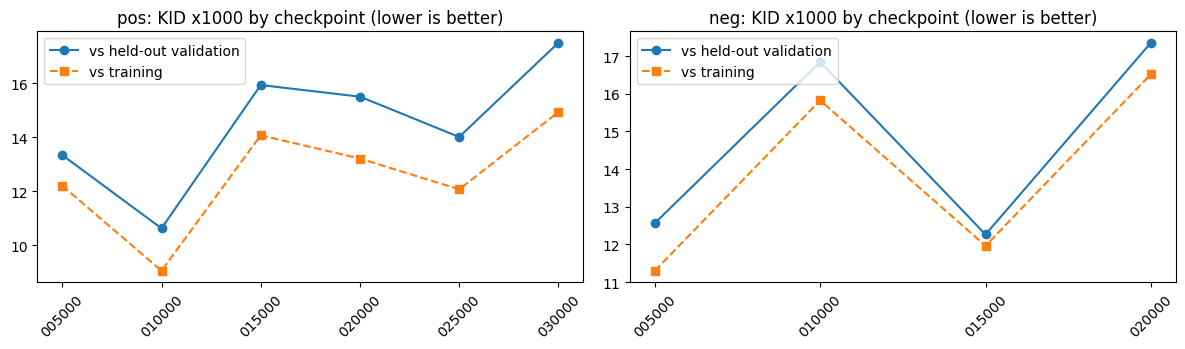

In [6]:
class Generator(nn.Module):                                  # identical to Notebook 3a
    def __init__(self, nz=NZ, ngf=NGF, nc=1, size=IMG_SIZE):
        super().__init__()
        depth = int(math.log2(size)) - 2; ch = ngf * 2 ** (depth - 1)
        layers = [nn.ConvTranspose2d(nz, ch, 4, 1, 0, bias=False), nn.BatchNorm2d(ch), nn.ReLU(True)]
        for _ in range(depth - 1):
            layers += [nn.ConvTranspose2d(ch, ch // 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ch // 2), nn.ReLU(True)]; ch //= 2
        layers += [nn.ConvTranspose2d(ch, nc, 4, 2, 1, bias=False), nn.Tanh()]
        self.net = nn.Sequential(*layers)
    def forward(self, z): return self.net(z)

@torch.no_grad()
def load_G(path):
    G = Generator().to(DEVICE); G.load_state_dict(torch.load(path, map_location=DEVICE)); return G.eval()

@torch.no_grad()
def sample(G, n, seed, bs=250):                              # identical to Notebook 3a
    g = torch.Generator(device=DEVICE).manual_seed(seed); out = []
    for i in range(0, n, bs):
        z = torch.randn(min(bs, n - i), NZ, 1, 1, device=DEVICE, generator=g)
        out.append(((G(z).clamp(-1, 1) + 1) * 127.5).round().byte().squeeze(1).cpu())
    return torch.cat(out).numpy()

rows, BEST = [], {}
for cls in ('pos', 'neg'):
    ckpts = sorted(glob(f'{CKPT_DIR}/{cls}_ema_it*.pt')) or [f'{CKPT_DIR}/{cls}_ema_final.pt']
    for ck in ckpts:
        a = resize_many(sample(load_G(ck), N_CKPT_SAMPLES, SEED + 100)); f, _ = xrv_feats(a)
        kv, kt = kid(f, FEAT[f'real_val_{cls}'][0])[0], kid(f, FEAT[f'real_train_{cls}'][0])[0]
        rows.append({'class': cls, 'checkpoint': os.path.basename(ck), 'KIDx1000_vs_val': 1000 * kv, 'KIDx1000_vs_train': 1000 * kt,
                     'diversity_MS-SSIM': diversity(a)})
ck_df = pd.DataFrame(rows); ck_df.to_csv(OUT / 'checkpoint_selection.csv', index=False)
for cls in ('pos', 'neg'):
    d = ck_df[ck_df['class'] == cls]
    BEST[cls] = FORCE_CKPT[cls] or d.loc[d['KIDx1000_vs_val'].idxmin(), 'checkpoint']
print(ck_df.round(3).to_string(index=False)); print('\nSelected checkpoints:', BEST)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a_, cls in zip(ax, ('pos', 'neg')):
    d = ck_df[ck_df['class'] == cls]; a_.plot(range(len(d)), d['KIDx1000_vs_val'], 'o-', label='vs held-out validation'); a_.plot(range(len(d)), d['KIDx1000_vs_train'], 's--', label='vs training')
    a_.set_xticks(range(len(d))); a_.set_xticklabels([c.replace(f'{cls}_ema_it', '').replace('.pt', '') for c in d['checkpoint']], rotation=45); a_.set_title(f'{cls}: KID x1000 by checkpoint (lower is better)'); a_.legend()
plt.tight_layout(); plt.show()

### 6. DC-GAN: Final Synthetic Images

Regenerates 5,000 pneumonia + 2,500 No Finding images with the selected checkpoints, using the same seeds and sampling function as Notebook 3a. If the selected checkpoint is the last one, the images are identical to those of 3a.

In [7]:
SYN128, drows = {}, []
for cls, label, seed in [('pos', 1, SEED), ('neg', 0, SEED + 1)]:
    ck = BEST[cls]; G = load_G(f'{CKPT_DIR}/{ck}'); arr = sample(G, N_SYN[cls], seed); SYN128[cls] = arr
    d = FINAL_DIR / ('pneumonia' if label else 'no_finding')
    for i, a in enumerate(arr):
        fn = f'dcgan_{cls}_{i:05d}.png'; Image.fromarray(a, 'L').save(d / fn)
        drows.append({'image': fn, 'folder': f'synthetic/dcgan_final/{d.name}', 'label': label, 'source': 'synthetic', 'generator': 'dcgan',
                      'img_size': IMG_SIZE, 'gen_seed': seed, 'index': i, 'checkpoint': ck, 'attempts': 1, 'degenerate': False,
                      'subset': 'only_2500' if (label == 0 or i < 2500) else 'extra_pos'})
dman = pd.DataFrame(drows); print(dman.groupby(['label', 'subset']).size().rename('images'))

label  subset   
0      only_2500    2500
1      extra_pos    2500
       only_2500    2500
Name: images, dtype: int64


### 7. RoentGen-v2: Load the Generated Images

The manifests of the Notebook 3b runs are merged (images flagged `degenerate` are excluded). The PNGs are located by file name inside the attached inputs.

In [8]:
rman = pd.concat([pd.read_csv(p) for p in RMAN], ignore_index=True).drop_duplicates('image', keep='last')
idx = {}
for p in RMAN:
    for sub in ('pneumonia', 'no_finding'):
        for f in glob(os.path.join(os.path.dirname(p), sub, '*.png')): idx[os.path.basename(f)] = f
rman['file'] = rman['image'].map(idx)
print('RoentGen-v2 manifest rows:', len(rman), '| PNG found:', int(rman.file.notna().sum()), '| degenerate:', int(rman.degenerate.sum()))
rman = rman[rman.file.notna() & (~rman.degenerate.astype(bool))].copy()
print(rman.groupby(['label', 'subset']).size().rename('images'))
for cls, label in (('pos', 1), ('neg', 0)):
    assert (rman.label == label).any(), f'no RoentGen-v2 images for class {cls}: attach the Notebook 3b run for that class'

def load_syn(path):
    return np.asarray(Image.open(path).convert('L').resize((EVAL_SIZE, EVAL_SIZE), Image.Resampling.LANCZOS), dtype=np.uint8)

SYN224 = {}
for cls, label in (('pos', 1), ('neg', 0)):
    s = rman[rman.label == label].sample(min(N_EVAL, int((rman.label == label).sum())), random_state=SEED)
    with ThreadPoolExecutor(8) as ex: SYN224[('roentgen', cls)] = np.stack(list(ex.map(load_syn, s['file'])))
    SYN224[('dcgan', cls)] = resize_many(SYN128[cls][:N_EVAL])
for (g, cls), a in SYN224.items(): featurise(f'{g}_{cls}', a)
print({k: v.shape for k, v in SYN224.items()})

RoentGen-v2 manifest rows: 7500 | PNG found: 7500 | degenerate: 0
label  subset   
0      only_2500    2500
1      extra_pos    2500
       only_2500    2500
Name: images, dtype: int64
{('roentgen', 'pos'): (1500, 224, 224), ('dcgan', 'pos'): (1500, 224, 224), ('roentgen', 'neg'): (1500, 224, 224), ('dcgan', 'neg'): (1500, 224, 224)}


### 8. Image Quality Metrics

For each generator and class. FID and KID are computed against the real training images of the same class (and KID also against the held-out validation images). For the DC-GAN, KID is also reported against the **resolution-matched** real images (real → 128 → 224), which removes the sharpness difference caused by its lower native resolution. SSIM is the mean SSIM between each synthetic image and its nearest real training image in feature space (300 images).

In [9]:
def nearest_idx(f_a, f_b):                                   # cosine nearest neighbour of each row of f_a in f_b
    a = torch.from_numpy(f_a); b = torch.from_numpy(f_b); a = F.normalize(a, dim=1); b = F.normalize(b, dim=1)
    sim = a @ b.T; v, i = sim.max(1); return (1 - v).numpy(), i.numpy()

qrows = []
for g in ('dcgan', 'roentgen'):
    for cls in ('pos', 'neg'):
        f, p, fi, pi = FEAT[f'{g}_{cls}']; rt = FEAT[f'real_train_{cls}']; rv = FEAT[f'real_val_{cls}']; rm = FEAT[f'realmat_train_{cls}']
        a = SYN224[(g, cls)]; ridx = rsel('train', cls, N_EVAL)
        r = {'generator': g, 'class': cls, 'n_syn': len(f), 'FID_xrv': fid(f, rt[0]), 'KIDx1000_xrv_train': 1000 * kid(f, rt[0])[0],
             'KIDx1000_xrv_val': 1000 * kid(f, rv[0])[0], 'KIDx1000_xrv_resmatched': 1000 * kid(f, rm[0])[0] if g == 'dcgan' else np.nan}
        if INC is not None:
            r.update({'FID_inc': fid(fi, rt[2]), 'KIDx1000_inc_train': 1000 * kid(fi, rt[2])[0], 'IS_inc': inception_score(pi), 'IS_inc_real': inception_score(rt[3])})
        sub = np.random.RandomState(0).choice(len(a), min(300, len(a)), replace=False)
        _, nn_i = nearest_idx(f[sub], rt[0])
        r['SSIM_to_nearest_real'] = float(ssim_pairs(a[sub], REAL_STD[ridx][nn_i]).mean())
        r['diversity_MS-SSIM_syn'] = diversity(a); r['diversity_MS-SSIM_real'] = diversity(REAL_STD[ridx])
        r['mean_intensity_syn'], r['mean_intensity_real'] = float(a.mean()), float(REAL_STD[ridx].mean())
        r['contrast_syn'], r['contrast_real'] = float(a.std(axis=(1, 2)).mean()), float(REAL_STD[ridx].std(axis=(1, 2)).mean())
        qrows.append(r)
qdf = pd.DataFrame(qrows); qdf.to_csv(OUT / 'quality_metrics.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print(qdf.round(3).T.to_string())

                               0        1         2         3
generator                  dcgan    dcgan  roentgen  roentgen
class                        pos      neg       pos       neg
n_syn                       1500     1500      1500      1500
FID_xrv                    5.454     6.49     6.129     3.752
KIDx1000_xrv_train         8.936   12.767     10.61     5.534
KIDx1000_xrv_val          10.606   13.589    12.739     4.605
KIDx1000_xrv_resmatched    2.553    1.428       NaN       NaN
FID_inc                  110.525   77.491    57.495    40.727
KIDx1000_inc_train       108.918   74.203    36.119    28.804
IS_inc                     1.988    1.982      2.45     2.319
IS_inc_real                2.725    2.682     2.725     2.682
SSIM_to_nearest_real       0.521    0.495      0.44     0.474
diversity_MS-SSIM_syn      0.507    0.496     0.395     0.435
diversity_MS-SSIM_real     0.412    0.433     0.412     0.433
mean_intensity_syn       115.815  126.834   134.238   134.242
mean_int

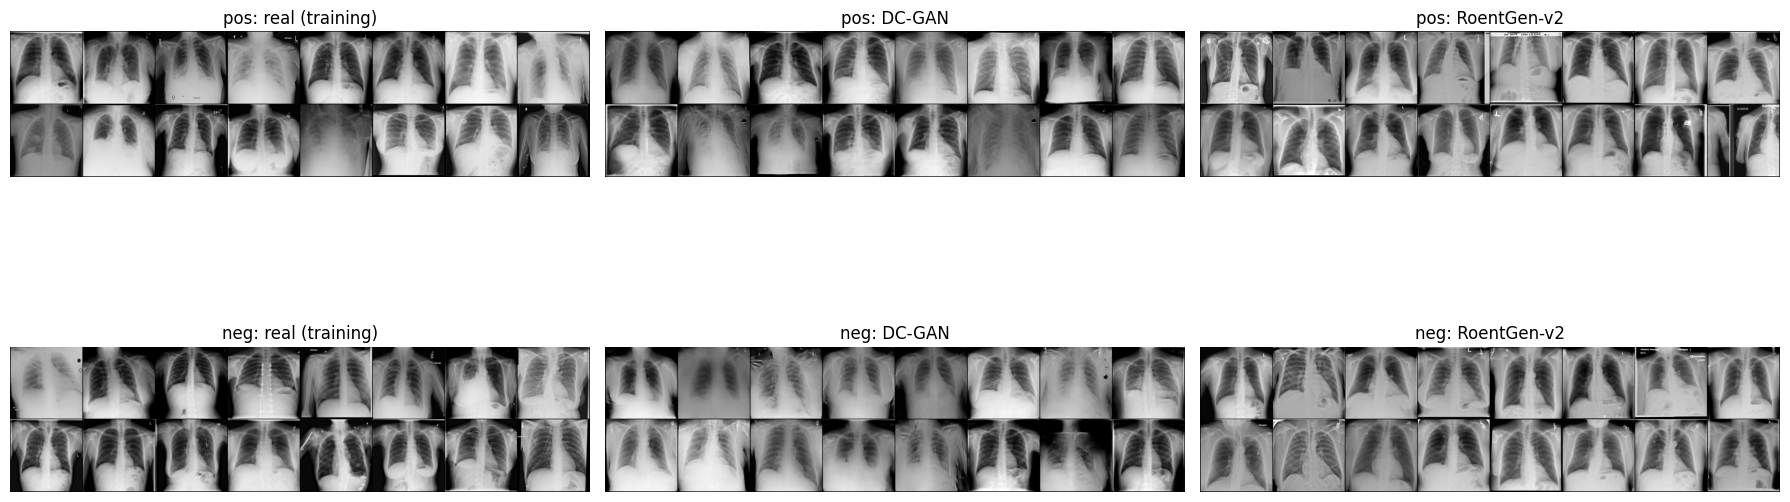

In [10]:
# Visual comparison: real | DC-GAN | RoentGen-v2 (first 16 of each, 224 px)
def grid(u8, n=16, nrow=8):
    from torchvision.utils import make_grid
    return make_grid(torch.from_numpy(u8[:n]).float().unsqueeze(1) / 255, nrow=nrow, padding=2)[0].numpy()
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for r_, cls in enumerate(('pos', 'neg')):
    for c_, (title, a) in enumerate([('real (training)', REAL_STD[rsel('train', cls, 16)]), ('DC-GAN', SYN224[('dcgan', cls)]), ('RoentGen-v2', SYN224[('roentgen', cls)])]):
        ax[r_, c_].imshow(grid(a), cmap='gray'); ax[r_, c_].set_title(f'{cls}: {title}'); ax[r_, c_].axis('off')
plt.tight_layout(); plt.show()

### 9. Real-versus-Synthetic Detector

If a simple classifier can tell real from synthetic images, a classifier trained on a mix will be able to do it too, and may use that signal as a shortcut (source = class), above all in scenarios 3 and 5, where 88% of the positives are synthetic. Two detectors are trained with 5-fold cross-validation, grouped by patient for real images: (a) logistic regression on TorchXRayVision features, and (b) gradient boosting on simple pixel statistics (mean, contrast, histogram, high-frequency energy). The AUROC is computed on held-out folds (0.5 = indistinguishable, 1.0 = trivially separable). It is also broken down by the view position of the real images, because RoentGen-v2 was trained on PA views only, and for the DC-GAN a resolution-matched real reference is added.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

def pixel_stats(u8):
    x = u8.astype(np.float32); lap = np.abs(x[:, 1:-1, 1:-1] * 4 - x[:, :-2, 1:-1] - x[:, 2:, 1:-1] - x[:, 1:-1, :-2] - x[:, 1:-1, 2:]).mean((1, 2))
    fft = np.abs(np.fft.rfft2(x)); h, w = fft.shape[1:]; hf = fft[:, h // 4: 3 * h // 4, w // 4:].sum((1, 2)) / (fft.sum((1, 2)) + 1e-6)
    hist = np.stack([np.histogram(a, bins=16, range=(0, 255))[0] / a.size for a in u8])
    return np.c_[x.mean((1, 2)), x.std((1, 2)), lap, hf, hist]

def detect(real_u8, real_f, real_groups, real_view, syn_u8, syn_f, seed=0):
    n = min(len(real_u8), len(syn_u8)); rng = np.random.RandomState(seed)
    ir, is_ = rng.choice(len(real_u8), n, replace=False), rng.choice(len(syn_u8), n, replace=False)
    y = np.r_[np.zeros(n), np.ones(n)]; groups = np.r_[real_groups[ir], 10_000_000 + np.arange(n)]; view = np.r_[real_view[ir], np.array(['syn'] * n)]
    cv = GroupKFold(5); out = {}
    for name, X, mdl in [('xrv_logreg', np.r_[real_f[ir], syn_f[is_]], make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))),
                         ('pixel_stats', np.r_[pixel_stats(real_u8[ir]), pixel_stats(syn_u8[is_])], HistGradientBoostingClassifier(random_state=seed))]:
        p = cross_val_predict(mdl, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
        out[name] = roc_auc_score(y, p)
        for v in ('AP', 'PA'):
            m = (view == v) | (view == 'syn')
            if (view == v).sum() > 5: out[f'{name}_real{v}'] = roc_auc_score(y[m], p[m])
    return out

drows = []
for g in ('dcgan', 'roentgen'):
    for cls in ('pos', 'neg'):
        ridx = np.concatenate([rsel('train', cls, N_EVAL), rsel('val', cls)])
        fr = np.r_[FEAT[f'real_train_{cls}'][0], FEAT[f'real_val_{cls}'][0]]; fm = np.r_[FEAT[f'realmat_train_{cls}'][0], FEAT[f'realmat_val_{cls}'][0]]
        grp, view = real_all['Patient ID'].values[ridx], real_all['view'].values[ridx]
        refs = [('real', REAL_STD[ridx], fr)] + ([('real_resmatched', REAL_MAT[ridx], fm)] if g == 'dcgan' else [])
        for rname, ru8, rf in refs:
            r = detect(ru8, rf, grp, view, SYN224[(g, cls)], FEAT[f'{g}_{cls}'][0]); drows.append({'generator': g, 'class': cls, 'real_reference': rname, **r})
ddf = pd.DataFrame(drows); ddf.to_csv(OUT / 'detector_results.csv', index=False)
print(ddf.round(3).to_string(index=False))

generator class  real_reference  xrv_logreg  xrv_logreg_realAP  xrv_logreg_realPA  pixel_stats  pixel_stats_realAP  pixel_stats_realPA
    dcgan   pos            real       1.000              0.999              1.000        1.000               1.000               1.000
    dcgan   pos real_resmatched       0.983              0.980              0.986        0.920               0.907               0.931
    dcgan   neg            real       1.000              1.000              1.000        1.000               1.000               1.000
    dcgan   neg real_resmatched       0.976              0.970              0.981        0.911               0.889               0.925
 roentgen   pos            real       0.998              1.000              0.996        0.989               0.988               0.991
 roentgen   neg            real       0.999              0.999              0.998        0.988               0.985               0.991


### 10. Memorisation Screen with Deep Features

For each synthetic image, the cosine distance (in TorchXRayVision feature space) to its nearest **training** image of the same class (`real_5k`) is compared with the same distance for real **held-out validation** images. If synthetic images are much closer to the training set than unseen real images are, the generator is probably copying. The share of synthetic images closer than the 1st and 5th percentile of the validation distances is reported (about 1% and 5% would be expected by chance if the distributions were equal). RoentGen-v2 was not trained on ChestX-ray14, so this test is only informative about the DC-GAN; it is shown for both for completeness (it cannot detect copying of MIMIC-CXR images).

generator class  median_dist_syn  median_dist_val  p1_val  pct_syn_below_val_p1  pct_syn_below_val_p5
    dcgan   pos           0.1306           0.0834  0.0223                   0.0                0.3333
    dcgan   neg           0.1033           0.0503  0.0215                   0.0                0.0000
 roentgen   pos           0.1030           0.0834  0.0223                   0.0                0.0000
 roentgen   neg           0.0776           0.0503  0.0215                   0.0                0.0667


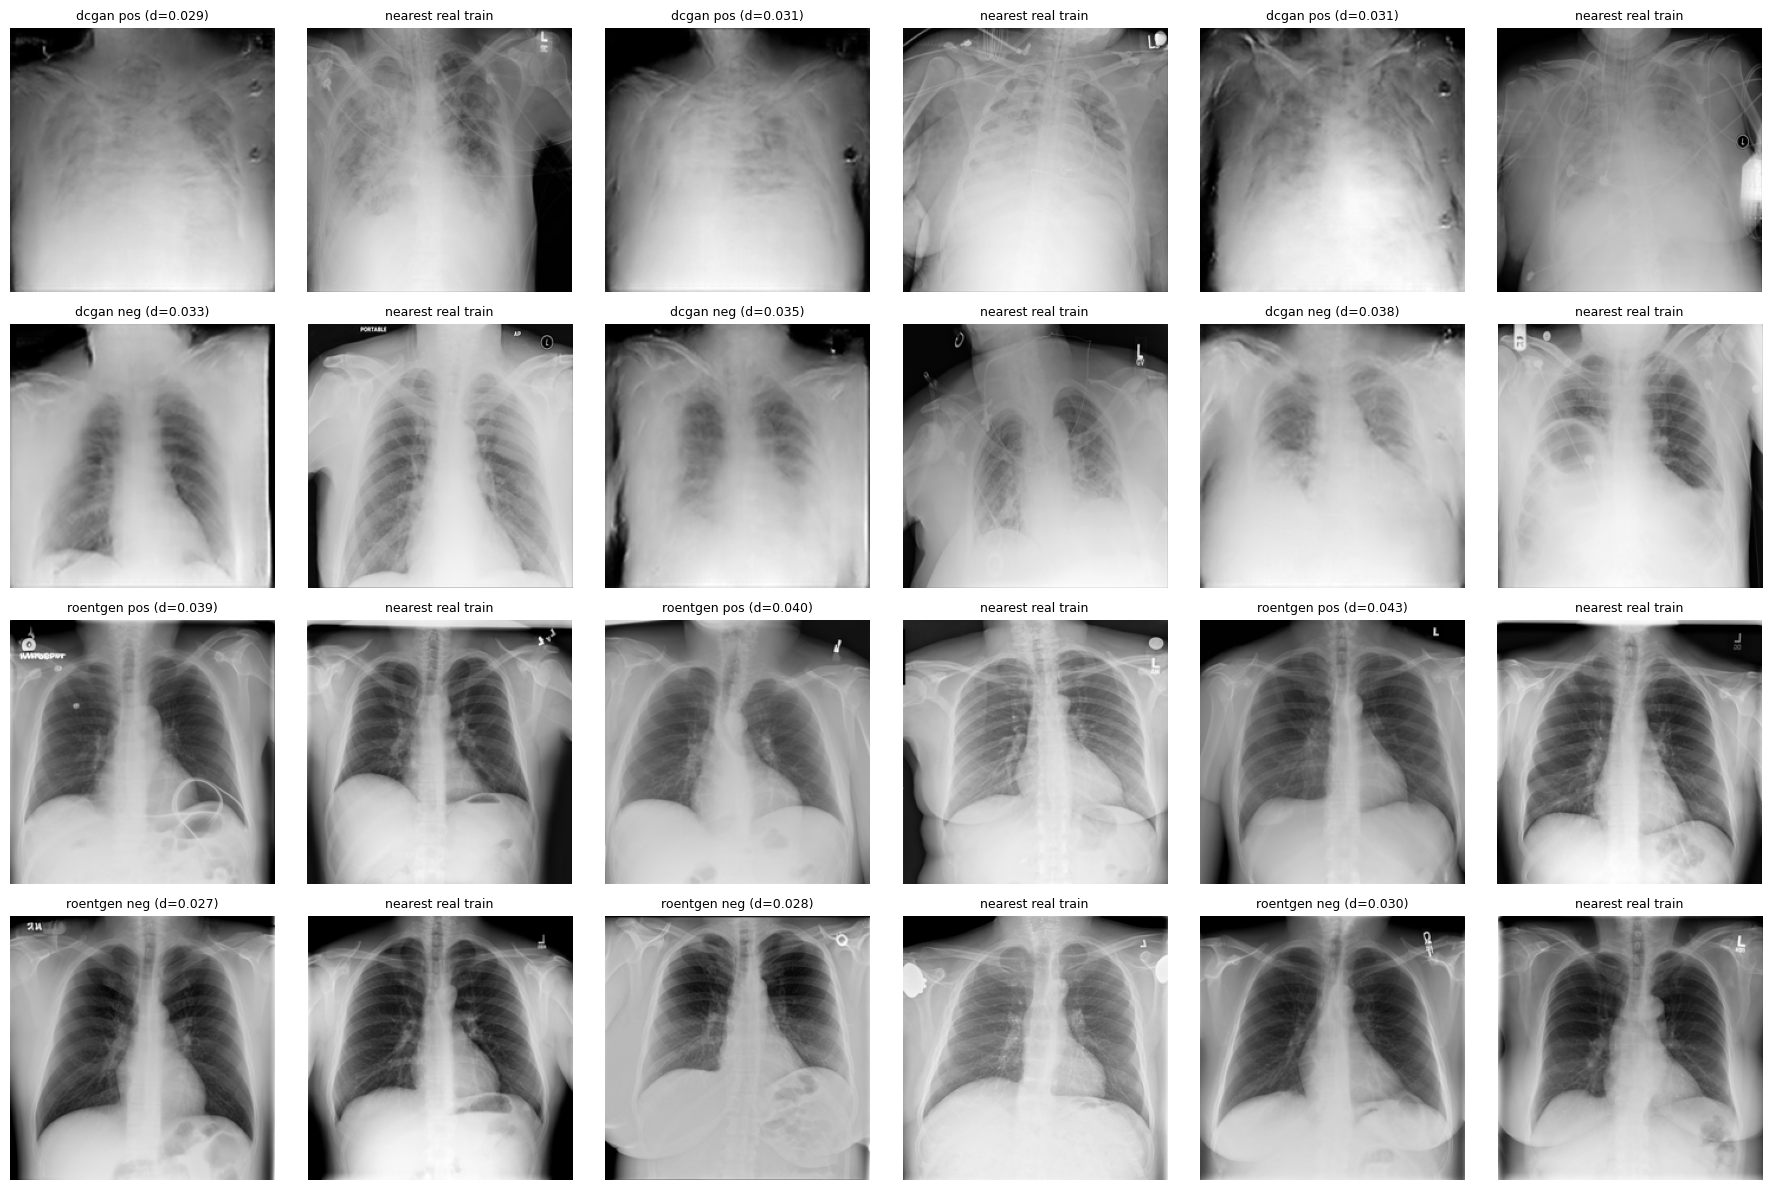

In [12]:
mrows, pairs_fig, FTR_ALL = [], {}, {}
for g in ('dcgan', 'roentgen'):
    for cls in ('pos', 'neg'):
        tr_idx = rsel('train', cls)                               # all training images of the class as reference
        if cls not in FTR_ALL: FTR_ALL[cls] = xrv_feats(REAL_STD[tr_idx])[0]
        ftr = FTR_ALL[cls]
        d_syn, i_syn = nearest_idx(FEAT[f'{g}_{cls}'][0], ftr); d_val, _ = nearest_idx(FEAT[f'real_val_{cls}'][0], ftr)
        p1, p5 = np.percentile(d_val, 1), np.percentile(d_val, 5)
        mrows.append({'generator': g, 'class': cls, 'median_dist_syn': np.median(d_syn), 'median_dist_val': np.median(d_val), 'p1_val': p1,
                      'pct_syn_below_val_p1': 100 * (d_syn < p1).mean(), 'pct_syn_below_val_p5': 100 * (d_syn < p5).mean()})
        order = np.argsort(d_syn)[:6]; pairs_fig[(g, cls)] = [(SYN224[(g, cls)][o], REAL_STD[tr_idx][i_syn[o]], d_syn[o]) for o in order]
mdf = pd.DataFrame(mrows); mdf.to_csv(OUT / 'memorisation.csv', index=False); print(mdf.round(4).to_string(index=False))

fig, ax = plt.subplots(4, 6, figsize=(18, 12))
for r_, ((g, cls), prs) in enumerate(pairs_fig.items()):
    for k, (s, t, d) in enumerate(prs[:3]):
        ax[r_, 2 * k].imshow(s, cmap='gray'); ax[r_, 2 * k].set_title(f'{g} {cls} (d={d:.3f})', fontsize=9); ax[r_, 2 * k + 1].imshow(t, cmap='gray'); ax[r_, 2 * k + 1].set_title('nearest real train', fontsize=9)
for a_ in ax.ravel(): a_.axis('off')
plt.tight_layout(); plt.show()

### 11. Alignment Diagnostic with TorchXRayVision

Does each generator really draw pneumonia when asked? The *Pneumonia* output of a TorchXRayVision DenseNet-121 is computed for every synthetic image, and the AUROC between synthetic pneumonia and synthetic normal images is reported, next to the same score on real images. That model was trained on datasets that include ChestX-ray14, so its AUROC on real data is optimistic and is shown only as a reference. This is a diagnostic: it is **not** used to select or discard images.

In [13]:
def auc(p, n): return roc_auc_score(np.r_[np.ones(len(p)), np.zeros(len(n))], np.r_[p, n])
arows = []
for g in ('dcgan', 'roentgen'):
    sp, sn = FEAT[f'{g}_pos'][1], FEAT[f'{g}_neg'][1]
    arows.append({'set': g, 'mean_score_pos': sp.mean(), 'mean_score_neg': sn.mean(), 'AUROC_pos_vs_neg': auc(sp, sn)})
rp, rn = np.r_[FEAT['real_train_pos'][1], FEAT['real_val_pos'][1]], np.r_[FEAT['real_train_neg'][1], FEAT['real_val_neg'][1]]
arows.append({'set': 'real (reference, optimistic)', 'mean_score_pos': rp.mean(), 'mean_score_neg': rn.mean(), 'AUROC_pos_vs_neg': auc(rp, rn)})
adf = pd.DataFrame(arows); adf.to_csv(OUT / 'xrv_alignment.csv', index=False); print(adf.round(3).to_string(index=False))

                         set  mean_score_pos  mean_score_neg  AUROC_pos_vs_neg
                       dcgan           0.240           0.066             0.719
                    roentgen           0.113           0.094             0.516
real (reference, optimistic)           0.450           0.204             0.741


### 12. Export the Final Manifest

`synthetic_final_manifest.csv` lists every synthetic image of both generators (all of them, not just the evaluation samples), with its subset (`only_2500` for scenarios 2 and 4, `extra_pos` for the 5,000 positives of scenarios 3 and 5). The classification notebooks locate the PNGs by file name inside the attached inputs: the DC-GAN images are in the output of this notebook (`synthetic/dcgan_final`) and the RoentGen-v2 images in the outputs of Notebook 3b.

In [14]:
rout = rman.assign(source='synthetic', generator='roentgen_v2', folder=lambda d: d['file'].map(lambda p: 'synthetic/roentgen/' + Path(p).parent.name), checkpoint='roentgen-v2')
cols = ['image', 'folder', 'label', 'source', 'generator', 'subset', 'img_size', 'gen_seed', 'checkpoint', 'attempts', 'degenerate']
final = pd.concat([dman[cols], rout.reindex(columns=cols)], ignore_index=True)
final['img_size'] = final['img_size'].fillna(512).astype(int)
final.to_csv(OUT / 'synthetic_final_manifest.csv', index=False); final.to_csv(WORK / 'synthetic_final_manifest.csv', index=False)
print(final.groupby(['generator', 'label', 'subset']).size().rename('images'))
print('\nFiles written to', OUT, ':', sorted(p.name for p in OUT.glob('*.csv')))

generator    label  subset   
dcgan        0      only_2500    2500
             1      extra_pos    2500
                    only_2500    2500
roentgen_v2  0      only_2500    2500
             1      extra_pos    2500
                    only_2500    2500
Name: images, dtype: int64

Files written to /kaggle/working/quality : ['checkpoint_selection.csv', 'detector_results.csv', 'memorisation.csv', 'quality_metrics.csv', 'synthetic_final_manifest.csv', 'xrv_alignment.csv']
